# Cross-validation

Companion notebook for the *Cross-validation* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn tool that does the same job.

**Data:** the Breast Cancer Wisconsin data (569 tumors, 30 measurements, malignant or benign).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
FOLD_COUNT = 5
NEIGHBOR_CHOICES = range(1, 32, 2)

X, y = load_breast_cancer(return_X_y=True)
model = make_pipeline(StandardScaler(), LogisticRegression())

## 1. k-fold cross-validation

Cut the shuffled rows into $k$ folds $F_1, \dots, F_k$. Train on $k-1$ folds, score on the one
left out, and repeat for every fold. The estimate is the average
$\text{CV}_{(k)} = \frac{1}{k}\sum_{m} s_m$.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
folds = np.array_split(rng.permutation(len(y)), FOLD_COUNT)

fold_scores = []
for test_rows in folds:
    train_rows = np.setdiff1d(np.arange(len(y)), test_rows)
    fitted = clone(model).fit(X[train_rows], y[train_rows])
    fold_scores.append(fitted.score(X[test_rows], y[test_rows]))

print("fold scores:", np.round(fold_scores, 3))
print(f"CV estimate {np.mean(fold_scores):.3f}, spread {np.std(fold_scores):.3f}")

fold scores: [0.965 0.991 0.965 0.974 0.991]
CV estimate 0.977, spread 0.012


In [3]:
same_folds = [(np.setdiff1d(np.arange(len(y)), test_rows), test_rows) for test_rows in folds]
library_scores = cross_val_score(model, X, y, cv=same_folds)
print("same scores on the same folds:", np.allclose(fold_scores, library_scores))

same scores on the same folds: True


In practice scikit-learn makes the folds itself:

In [4]:
scores = cross_val_score(model, X, y, cv=StratifiedKFold(FOLD_COUNT, shuffle=True, random_state=RANDOM_STATE))
print(f"CV estimate {scores.mean():.3f} ± {scores.std():.3f}")

CV estimate 0.974 ± 0.017


`StratifiedKFold` builds the folds class by class, so every fold keeps the share of malignant tumors.

## 2. Choosing a setting

Try each value of a setting and keep the one with the best cross-validated score:
$\hat{\theta} = \arg\max_\theta \text{CV}_{(k)}(\theta)$. Here the setting is the number of neighbors in k-nearest neighbors.

best number of neighbors: 7


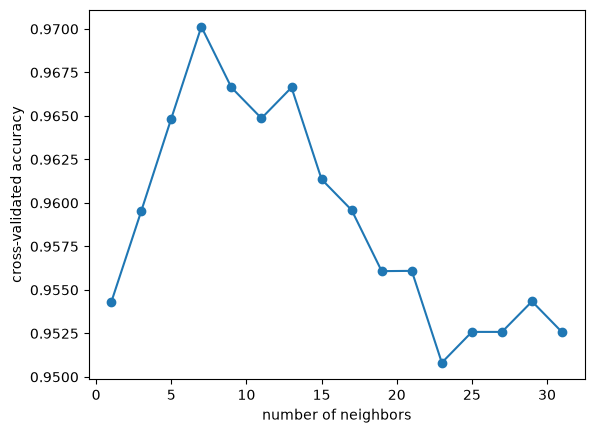

In [5]:
cv_accuracy = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), X, y, cv=FOLD_COUNT).mean()
               for k in NEIGHBOR_CHOICES]
best_by_hand = list(NEIGHBOR_CHOICES)[int(np.argmax(cv_accuracy))]
print("best number of neighbors:", best_by_hand)

plt.plot(list(NEIGHBOR_CHOICES), cv_accuracy, marker="o")
plt.xlabel("number of neighbors")
plt.ylabel("cross-validated accuracy")
plt.show()

In [6]:
search = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                      {"kneighborsclassifier__n_neighbors": list(NEIGHBOR_CHOICES)}, cv=FOLD_COUNT)
search.fit(X, y)
print("same choice:", search.best_params_["kneighborsclassifier__n_neighbors"] == best_by_hand)

same choice: True


## 3. The honest protocol

Keep a test set aside, choose the setting with cross-validation on the training part only,
and score the final model once on the test set.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
search.fit(X_train, y_train)
print("chosen:", search.best_params_, f"| test accuracy {search.score(X_test, y_test):.3f}")

chosen: {'kneighborsclassifier__n_neighbors': 7} | test accuracy 0.974


## Exercises

1. Repeat section 1 with $k = 2$ and $k = 10$. How do the average and the spread change?
2. Use `LeaveOneOut()` as `cv` in `cross_val_score`. How many models does it train?
3. Write the stratified folds by hand: split the rows of each class into $k$ parts and join them.